# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [16]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
 

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv("clientes_ecommerce.csv")

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [17]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [18]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [19]:
# TODO: muestra los nombres de las columnas
df.columns
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [20]:
# TODO: consulta los tipos de datos
df.dtypes
for k,v in df.dtypes.items():
    print(f"Columna: {k} | Tipo: {v}")

Columna: cliente_id | Tipo: int64
Columna: edad | Tipo: int64
Columna: antiguedad_meses | Tipo: float64
Columna: ingresos_anuales | Tipo: float64
Columna: gasto_mensual | Tipo: float64
Columna: num_compras | Tipo: int64
Columna: devoluciones | Tipo: int64
Columna: dispositivo | Tipo: str
Columna: zona | Tipo: str
Columna: nivel_fidelidad | Tipo: str
Columna: satisfaccion | Tipo: int64
Columna: compra_proximo_mes | Tipo: str


In [21]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Responde

1. ¿Cuántas muestras contiene?
400
2. ¿Cuántas columnas?
12 columnas
3. ¿Cuál es la unidad de observación?
un cliente
4. ¿Cuál es el identificador?
cliente_id
5. ¿Cuál es el target?
compra_proximo_meses
6. ¿Qué columnas tienen valores ausentes?
antiguedad_meses, ingresos anuales, gasto_mensual


# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [22]:
# TODO: muestra describe() para gasto_mensual
print(df["gasto_mensual"].describe().round(2))
print(f"Mediana: {df['gasto_mensual'].median()}")
print("Q1: ",df["gasto_mensual"].quantile(.25))
print("Q2: ",df["gasto_mensual"].quantile(.5))
print("Q3: ",df["gasto_mensual"].quantile(.75))


# TODO: calcula las medidas necesarias

count    397.00
mean      69.09
std       39.02
min        5.77
25%       39.72
50%       61.17
75%       90.15
max      260.00
Name: gasto_mensual, dtype: float64
Mediana: 61.17
Q1:  39.72
Q2:  61.17
Q3:  90.15


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69.09 |
| Mediana | 61.17 |
| Desviación estándar | 39.02 |
| Mínimo | 5.77 |
| Q1 | 39.72 |
| Q2 | 61.17 |
| Q3 | 90.15 |
| Máximo | 260.00 |

### Interpreta

1. ¿Coinciden exactamente media y mediana?
No
2. ¿Cuál es mayor?
Media
3. ¿Qué puede indicar esta diferencia sobre la distribución?
Que la tabla va a estar hacia la derecha (asismetria positiva)
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?
entre Q1 y Q3.
**Respuesta:**  
Escribe aquí.

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

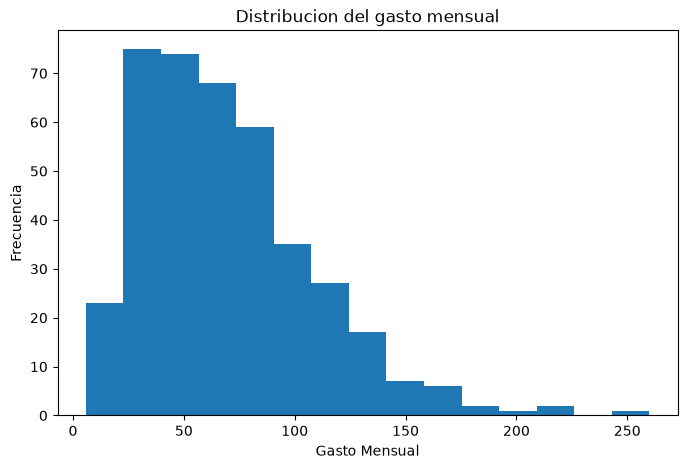

In [23]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df["gasto_mensual"].dropna(), bins=15)
plt.xlabel("Gasto Mensual")
plt.ylabel("Frecuencia")
plt.title("Distribucion del gasto mensual")
plt.show()

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
entre los valores 40 y 70
2. ¿La distribución parece aproximadamente simétrica?
No, no es simetrica
3. ¿Existe una cola hacia valores altos o bajos?
Si, existe la cola hacia la derecha
4. ¿Observas valores alejados del resto?
si, unos valores sueltos entre el 200 - 210 y unos en el 250

**Respuesta:**  
Escribe aquí.

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

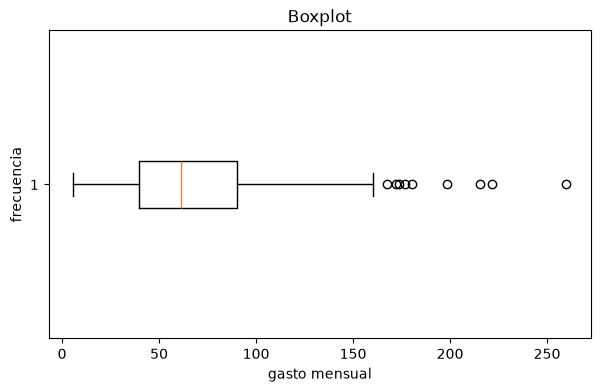

In [24]:
# TODO: crea un boxplot de gasto_mensual
plt.figure(figsize=(7,4))
plt.boxplot(df["gasto_mensual"].dropna(),orientation="horizontal")
plt.xlabel("gasto mensual")
plt.ylabel("frecuencia")
plt.title("Boxplot")
plt.show()


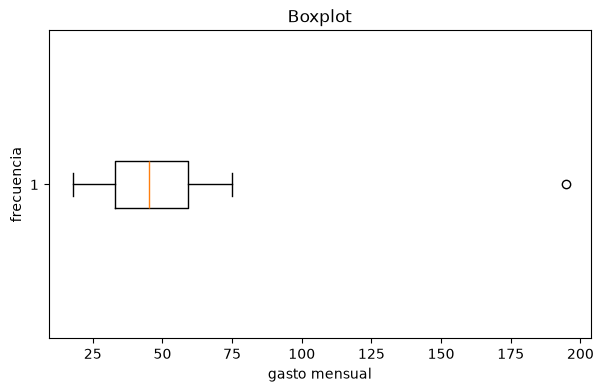

In [25]:
plt.figure(figsize=(7,4))
plt.boxplot(df["edad"].dropna(),orientation="horizontal")
plt.xlabel("gasto mensual")
plt.ylabel("frecuencia")
plt.title("Boxplot")
plt.show()

In [26]:
# TODO: calcula Q1, Q3 e IQR
Q1 = df["edad"].quantile(.25)
Q2 = df["edad"].quantile(.5)
Q3 = df["edad"].quantile(.75)

#Rango intercuantilico
IQR = Q3 - Q1
# TODO: calcula los límites inferior y superior
Linf_edad = Q1 - 1.5 * IQR
Lsup_edad = Q3 + 1.5 * IQR


# TODO: muestra los resultados
print(f"IQR : {IQR:.2f} , Limite inferior: {Linf:.2f} ,  Limite inferior: {Lsup:.2f}")

NameError: name 'Linf' is not defined

### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
Por el 47 mas o menos
2. ¿Observas posibles outliers?
si, uno en el 190
3. ¿Aparecen principalmente por encima o por debajo?
por debajo

4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.
No, aun que sean valores que se alejen, solamente mirandolo no podemos afirmarlo ya que puede ser alguien real pagandolo
**Respuesta:**  
Escribe aquí.

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [ ]:
# TODO: calcula Q1, Q3 e IQR
Q1 = df["gasto_mensual"].quantile(.25)
Q2 = df["gasto_mensual"].quantile(.5)
Q3 = df["gasto_mensual"].quantile(.75)

#Rango intercuantilico
IQR = Q3 - Q1
# TODO: calcula los límites inferior y superior
Linf = Q1 - 1.5 * IQR
Lsup = Q3 + 1.5 * IQR


# TODO: muestra los resultados
print(f"IQR : {IQR:.2f} , Limite inferior: {Linf:.2f} ,  Limite inferior: {Lsup:.2f}")

IQR : 50.43 , Limite inferior: -35.93 ,  Limite inferior: 165.80


In [ ]:
# TODO: crea outliers_gasto
outliers_gasto = df[
    (df["gasto_mensual"] < Linf) |
    (df["gasto_mensual"] > Lsup)
]
# TODO: muestra los posibles outliers
display(outliers_gasto)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


In [ ]:
# TODO: crea edad
edad = df[
    (df["edad"] < Linf_edad) |
    (df["edad"] > Lsup_edad)
]
# TODO: muestra los posibles outliers
display(edad)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
137,20138,195,106.0,32593.41,138.99,6,0,Móvil,Este,Plata,3,No


### Responde

1. ¿Cuántos posibles outliers has encontrado?
9 posible outliers
2. ¿Qué porcentaje representan?
2.25
3. ¿Cuál es el mayor `gasto_mensual`?
40391.73
4. ¿Eliminarías automáticamente estas observaciones?
No, ya que se pueden usar para ver los errores
5. ¿Qué investigarías antes?
Si estos son reales
**Respuesta:**  
Escribe aquí.

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [ ]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
print(df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].describe())

             edad  ingresos_anuales  gasto_mensual  num_compras  devoluciones
count  400.000000        396.000000     397.000000   400.000000    400.000000
mean    46.402500      36440.920379      69.089320     8.225000      1.225000
std     18.007809      14325.228166      39.023238     2.780955      1.136929
min     18.000000       9000.000000       5.770000     2.000000      0.000000
25%     33.000000      26034.092500      39.720000     6.000000      0.000000
50%     45.000000      36817.275000      61.170000     8.000000      1.000000
75%     59.000000      45969.032500      90.150000    10.000000      2.000000
max    195.000000      82925.370000     260.000000    17.000000      5.000000


In [ ]:
# TODO: calcula sus medianas
print(df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].median())

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64


Text(0.5, 1.0, 'Historgrama de edad')

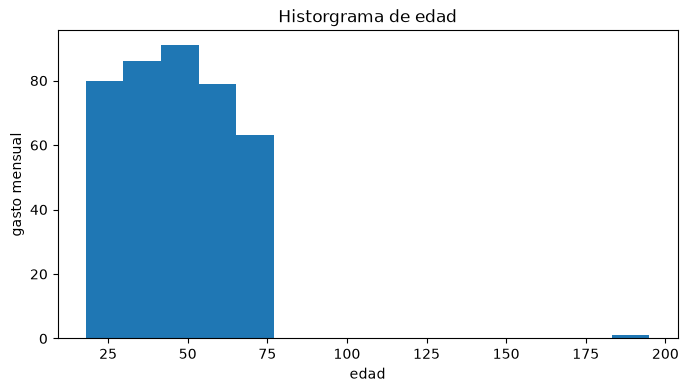

In [ ]:
# TODO: histograma de edad
plt.figure(figsize=(8,4))
plt.hist(df["edad"].dropna(), bins=15)
plt.xlabel("edad")
plt.ylabel("frecuencia")
plt.title("Historgrama de edad")
plt.show()

Text(0.5, 1.0, 'ingresos')

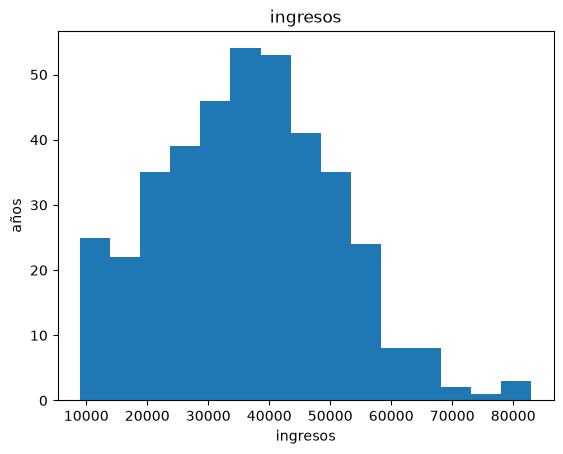

In [ ]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8,5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15)
plt.xlabel("ingresos")
plt.ylabel("frecuencia")
plt.title("ingresos")
plt.show()

Text(0.5, 1.0, 'gasto')

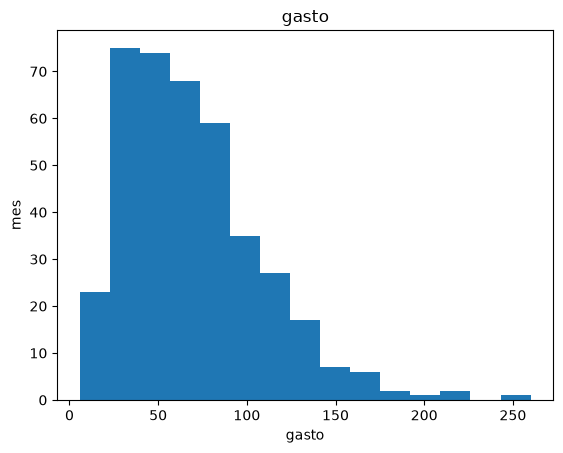

In [ ]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df["gasto_mensual"].dropna(), bins=15)
plt.xlabel("gasto")
plt.ylabel("frecuencia")
plt.title("gasto")
plt.show()

Text(0.5, 1.0, 'ingresos')

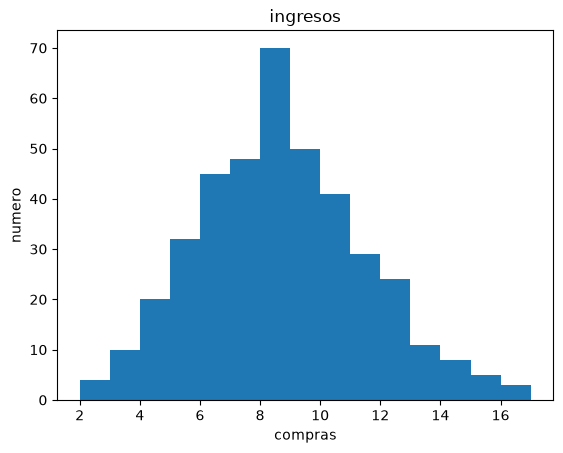

In [ ]:
# TODO: histograma de num_compras
plt.figure(figsize=(8,5))
plt.hist(df["num_compras"].dropna(), bins=15)
plt.xlabel("compras")
plt.ylabel("frecuencia")
plt.title("compras")
plt.show()

Text(0.5, 1.0, 'devoluciones')

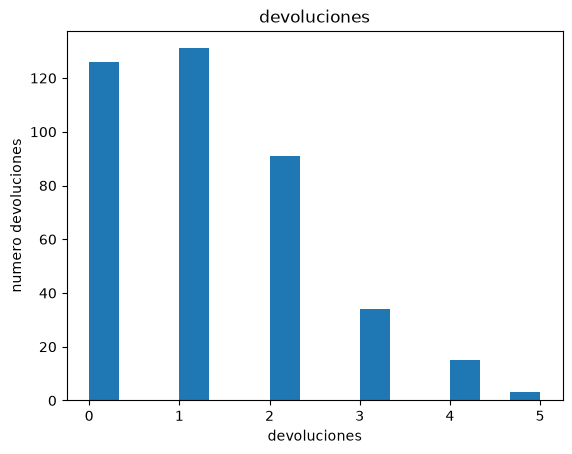

In [ ]:
# TODO: histograma de devoluciones
plt.figure(figsize=(8,5))
plt.hist(df["devoluciones"].dropna(), bins=15)
plt.xlabel("devoluciones")
plt.ylabel("frecuencia")
plt.title("devoluciones")
plt.show()

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46.40 | 45.00 | 18 | 195 | Máximo de 195 años: imposible, muy alejado del resto (el siguiente valor es 75) |
| ingresos_anuales | 36440.92 | 36817.28 | 9000.00 | 82925.37 | 4 nulos; 16 clientes con exactamente 9000, parece un valor mínimo impuesto |
| gasto_mensual | 69.09 | 61.17 | 5.77 | 260.00 | 3 nulos; asimetría a la derecha (media > mediana) y 9 outliers por arriba |
| num_compras | 8.23 | 8.00 | 2 | 17 | Distribución bastante simétrica (media ≈ mediana) |
| devoluciones | 1.23 | 1.00 | 0 | 5 | Valores bajos y discretos; muchos clientes con 0 devoluciones |

### Busca una observación sospechosa

- ¿Qué variable es?
edad
- ¿Qué valor tiene?
195 años (cliente 20138)
- ¿Por qué parece sospechoso?
Porque es una edad imposible para una persona
- ¿Es un outlier?
Sí. Supera el límite superior del IQR (Q3 + 1.5·IQR = 59 + 1.5·26 = 98).
- ¿Podemos afirmar directamente que es un error?
En este caso es casi seguro que es un error de registro
- ¿Qué harías antes de modificarlo?
Revisar el resto de datos de ese cliente, consultar la fuente original de los datos.

**Respuesta:**  
La variable sospechosa es edad, con un valor de 195 años. Es un outlier según el IQR y casi con seguridad un error de registro, pero antes de modificarlo habría que comprobarlo con la fuente de los datos. Pero tampoco hace falta ver el outlier para saber si es error o no en este caso

# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [ ]:
# TODO: analiza dispositivo
print(df["dispositivo"].value_counts())
print(df["dispositivo"].value_counts(normalize=True)*100)



dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64


In [ ]:
# TODO: analiza zona
print(df["zona"].value_counts())
print(df["zona"].value_counts(normalize=True).round(4))
print(df["zona"].value_counts(normalize=True)*100)

zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64


In [ ]:
# TODO: analiza nivel_fidelidad
print(df["nivel_fidelidad"].value_counts())
print(df["nivel_fidelidad"].value_counts(normalize=True).round(4))
print(df["nivel_fidelidad"].value_counts(normalize=True)*100)

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64


In [ ]:
# TODO: analiza compra_proximo_mes
print(df["compra_proximo_mes"].value_counts())
print(df["compra_proximo_mes"].value_counts(normalize=True).round(4))
print(df["compra_proximo_mes"].value_counts(normalize=True)*100)

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    0.615
Sí    0.385
Name: proportion, dtype: float64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50 % |
| zona | Este | 89 | 22.25 % |
| nivel_fidelidad | Bronce | 162 | 40.50 % |
| compra_proximo_mes | No | 246 | 61.50 % |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

Index(['Móvil', 'Ordenador', 'Tablet'], dtype='str', name='dispositivo')


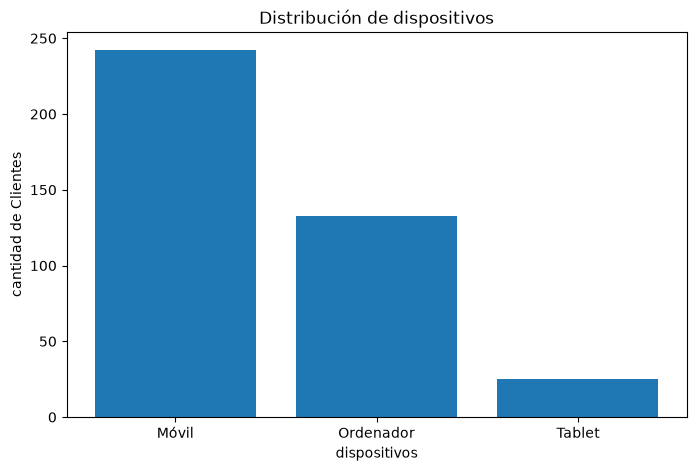

In [30]:
# TODO: gráfico de barras de dispositivo
conteos_disp = df["dispositivo"].value_counts()
print(conteos_disp.index)

plt.figure(figsize=(8,5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.xlabel("dispositivos")
plt.ylabel("cantidad de Clientes")
plt.title("Distribución de dispositivos")
plt.show()

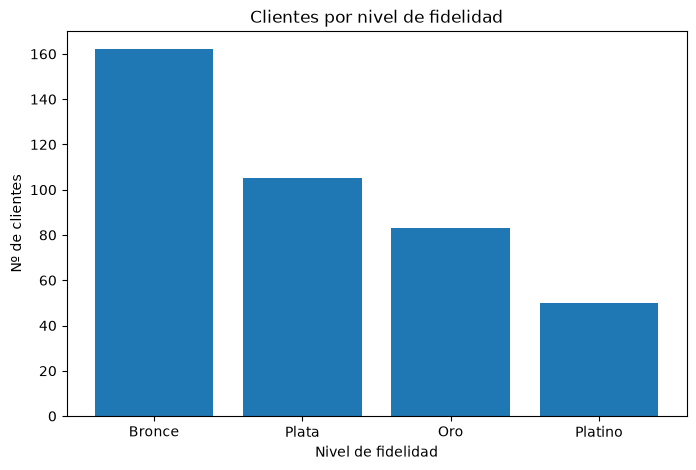

In [31]:
# TODO: gráfico de barras de nivel_fidelidad
conteos_fid = df["nivel_fidelidad"].value_counts().reindex(["Bronce", "Plata", "Oro", "Platino"])

plt.figure(figsize=(8,5))
plt.bar(conteos_fid.index, conteos_fid.values)
plt.xlabel("Nivel de fidelidad")
plt.ylabel("Nº de clientes")
plt.title("Clientes por nivel de fidelidad")
plt.show()

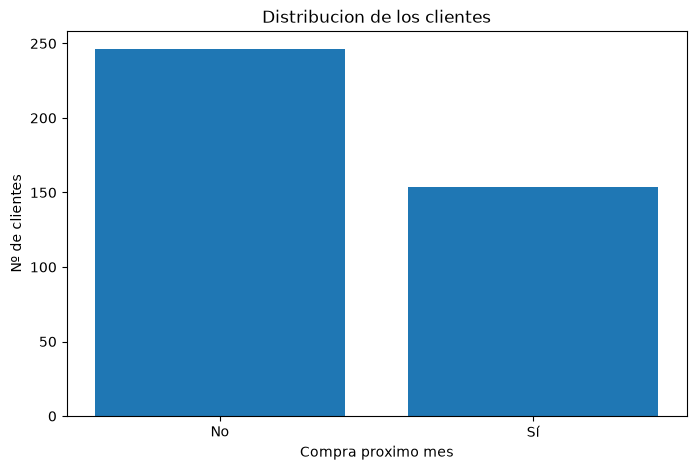

In [32]:
# TODO: gráfico de barras de compra_proximo_mes
conteos_fid = df["compra_proximo_mes"].value_counts()

plt.figure(figsize=(8,5))
plt.bar(conteos_fid.index, conteos_fid.values)
plt.xlabel("Compra proximo mes")
plt.ylabel("Nº de clientes")
plt.title("Distribucion de los clientes")
plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**  
Escribe aquí.

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

     num_compras  gasto_mensual
0              7          60.73
1              6         131.74
2              8          55.33
3              7          24.33
4              5          88.78
..           ...            ...
395            6          19.48
396            3          98.96
397           16          48.39
398           10         260.00
399           12          37.70

[400 rows x 2 columns]


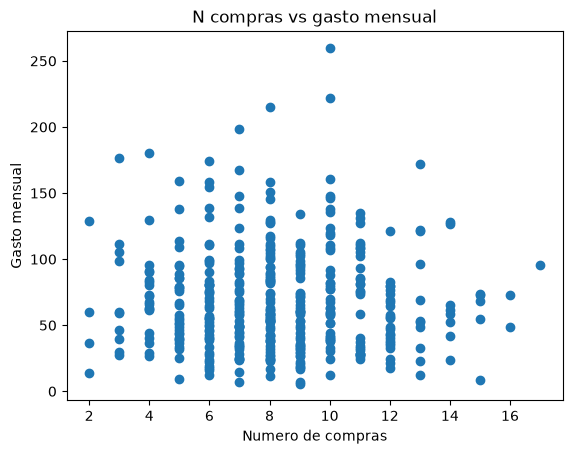

In [40]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.Figure(figsize=(8,5))
print(df[["num_compras" ,"gasto_mensual"]])
plt.scatter(df["num_compras"], df["gasto_mensual"])
plt.xlabel("Numero de compras")
plt.ylabel("Gasto mensual")
plt.title("N compras vs gasto mensual")
plt.show()

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**  
Escribe aquí.

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [50]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
print(df["num_compras"].corr(df["gasto_mensual"]).round(4))
print(df["edad"].corr(df["gasto_mensual"]).round(4))
#si el dato es mas proximo a 0 no hay correlación
#proximo a 1 correlacion postiva 
#proximo a -1 correlacion negativa 

-0.0142
0.0214


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**  
Escribe aquí.

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [ ]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
df.select_dtypes(include="number").drop(columns=["cliente_id"])

# TODO: calcula y muestra la matriz de correlaciones

### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1?
2. ¿Por qué la matriz es simétrica?
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta?
4. ¿Qué pareja presenta la correlación más negativa?
5. ¿Hay variables cuya correlación sea prácticamente cero?

**Respuesta:**  
Escribe aquí.

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

In [ ]:
# TODO: representa la matriz de correlaciones con plt.imshow()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. 
2. 
3. 

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [ ]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas

### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**  
Escribe aquí.

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

In [ ]:
# TODO: crea grupo_no y grupo_si


# TODO: representa ambos grupos mediante un boxplot

### Interpreta

1. ¿Qué grupo presenta una mediana mayor?
2. ¿Cuál parece tener mayor dispersión?
3. ¿Existen outliers en ambos?
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`?

**Respuesta:**  
Escribe aquí.

# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [ ]:
# TODO: tabla de contingencia con frecuencias absolutas

In [ ]:
# TODO: tabla normalizada por filas

In [ ]:
# TODO: muestra las proporciones como porcentajes

### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran?
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran?
3. ¿Coinciden necesariamente ambas respuestas?
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?

**Respuesta:**  
Escribe aquí.

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

Escribe aquí.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

In [ ]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada

### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

**Respuesta:**  
Escribe aquí.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [ ]:
# TODO: comparación numérica

In [ ]:
# TODO: primera visualización

In [ ]:
# TODO: comparación categórica y tabla de proporciones

In [ ]:
# TODO: segunda visualización

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**  
Escribe aquí.

# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

### Hallazgo 1
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 2
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 3
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 4
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 5
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

Escribe aquí.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`